# 8. k-NN

No training formula: a borrower's risk is the distance-weighted share of defaulters among its k nearest
neighbours (standardised features, defaulters up-weighted). k is picked on the validation set from a grid.

From-scratch code: `ClassificationAlgorithms/KNN.py` · charts: `Images/Classification/08_KNN/` · tables: `Results/Classification/08_KNN/`

## 1. Setup and data

In [1]:
# Setup: imports, data and the fixed 60/20/20 train/validation/test split (seed 42)
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "Common")))

import numpy as np
from project import SEED, Outputs, classification_data
from metrics_classification import roc_auc
from model_zoo import check_settings
from report_classification import report_classifier, sklearn_check
from KNN import KNNClassifierScratch
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

out = Outputs("Classification", "08_KNN")
d = classification_data()
print(
    f"train {d.X_tr.shape} | validation {d.X_va.shape} | test {d.X_te.shape} | "
    f"{len(d.feature_cols)} features | {d.y.mean():.1%} defaulters"
)

train (5746, 27) | validation (1916, 27) | test (1916, 27) | 27 features | 16.0% defaulters


## 2. Model

In [2]:
# Model: build the from-scratch model and train it (validation set = early stopping)
model = KNNClassifierScratch(
    n_neighbors=25, weights="distance", tune_k="auto", scale_pos_weight="balanced", random_state=SEED
)
check_settings("k-NN", model)
model.fit(d.X_tr, d.y_tr, eval_set=[(d.X_va, d.y_va)], feature_names=d.feature_cols, early_stopping_rounds=30)
p_te = model.predict_proba(d.X_te)[:, 1]

# verification: scikit-learn KNeighborsClassifier with the k chosen above
k = int(model.n_neighbors_)
print(f"k chosen on the validation set: k = {k} (best validation {model.k_selection_.get('metric', 'auc')})")
sc = StandardScaler().fit(d.X_tr)
sk = KNeighborsClassifier(n_neighbors=k, weights="distance").fit(sc.transform(d.X_tr), d.y_tr)
p_sk = sk.predict_proba(sc.transform(d.X_te))[:, 1]
check = sklearn_check(
    f"k-NN vs sklearn KNeighborsClassifier (k={k}, distance weights)",
    np.abs(p_te - p_sk).max(),
    roc_auc(d.y_te, p_te),
    roc_auc(d.y_te, p_sk),
    "max |dP|",
)

settings match Common/model_zoo.py (12 values checked)


k chosen on the validation set: k = 41 (best validation auc)


## 3. Results

                                  test set  at plain 0.5
threshold (chosen on validation)    0.1306        0.5000
log loss                            0.4294           NaN
accuracy                            0.4880        0.8408
precision                           0.2045        0.0000
recall / sensitivity                0.7672        0.0000
specificity                         0.4351           NaN
F1                                  0.3230        0.0000
ROC-AUC                             0.6501           NaN
PR-AUC                              0.2591           NaN
defaulters missed (FN)             71.0000           NaN

catches 76.7% of the 305 test defaulters (71 missed), flags 59.7% of applicants


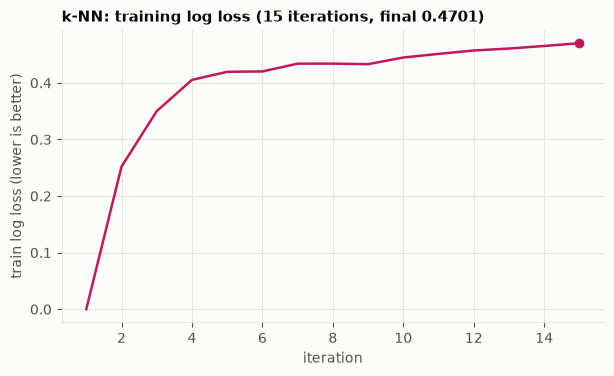

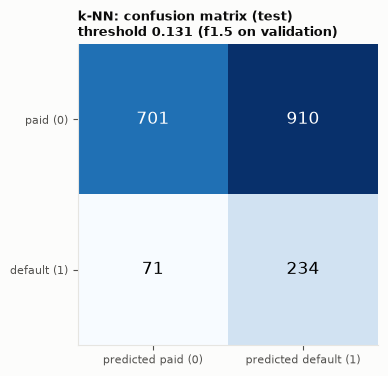

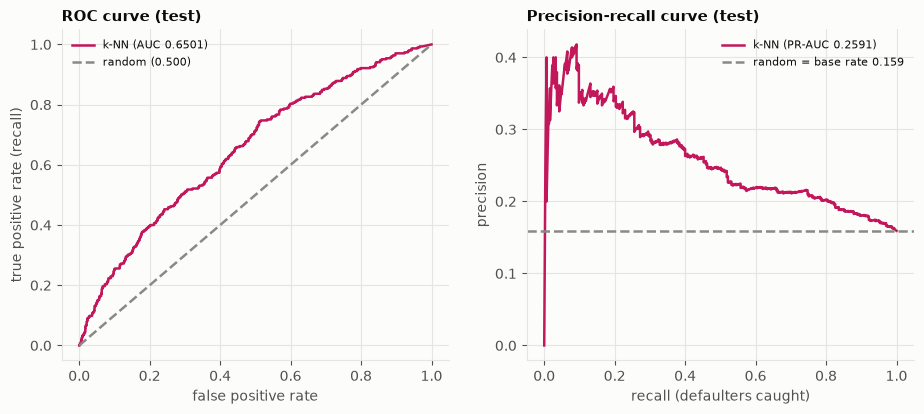

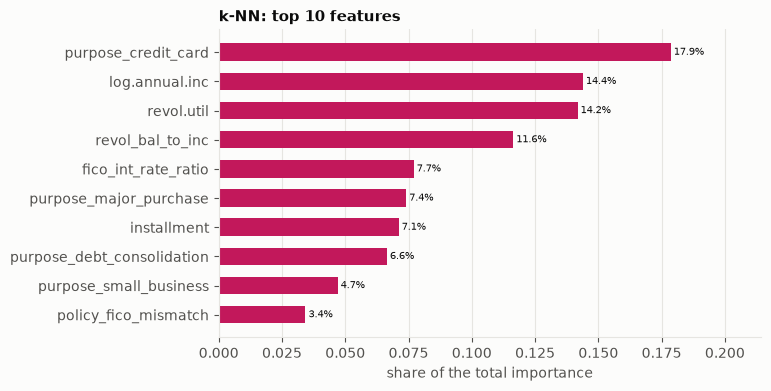


scratch vs library:
  k-NN vs sklearn KNeighborsClassifier (k=41, distance weights)
    AUC scratch 0.6501 | AUC library 0.6528 | max |dP| = 0.32



saved + reloaded TrainedModels/Classification/08_KNN.joblib (identical predictions: True)


In [3]:
# Results: metrics at the validation-chosen threshold, charts, scratch-vs-library check, saved model
row = report_classifier(out, "k-NN", model, d, check)